# Módulo 5 — Pipeline completo:

**Objetivo:** a partir de un video del ojo, recorrerlo frame a frame y, en cada uno:

1. Extraer el frame y recortar la ROI.
2. Pasarlo a escala de grises.
3. Segmentar la pupila con **Watershed** sobre el gradiente de Sobel (Módulo 2).
4. Aplicar **erosión** morfológica y quedarse con la componente conexa principal (Módulo 2.2 / 3.1).
5. Calcular las **características** del punto 3.1: morfometría (área, perímetro, diámetro
   equivalente, circularidad, excentricidad), textura de primer orden y GLCM (segundo orden).
6. Repetir 1–4 en **todos los frames** del video para armar las curvas temporales $A(t)$ y
   $D(t)$, limpiarlas de artefactos y suavizarlas para poder derivarlas.

**Cómo usar con otro video:** solo hay que cambiar `VIDEO_PATH` y `ROI` en la celda de
parámetros (sección 1). El resto de la configuración (CLAHE, Watershed, morfología, filtros
de artefactos, suavizado) sale de `config.yaml`, igual que en el resto de los notebooks del TP.

Toda la lógica de cálculo vive en `src/` (Módulos 1, 2 y 3); este notebook solo la llama y
grafica. Las fórmulas de cada paso se explican en las celdas de texto, con la referencia a
la función de `src/` que las implementa.

## 0. Preparación del entorno

El notebook vive en `notebooks/`, pero el código está en `src/`. Se agrega la **raíz del
repo** a `sys.path` para poder hacer `from src... import ...` (misma lógica que en
`01_1_carga_muestreo_color.ipynb`).

In [1]:
# --- Imports de la librería estándar ---
import sys
from pathlib import Path

# --- Encontrar la raíz del repo (carpeta que contiene config.yaml) ---
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros ---
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# --- Imports propios ---
from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm
from src.modulo1 import calidad_filtrado as cf
from src.modulo2 import segmentacion as seg
from src.modulo2 import morfologia as morf
from src.modulo3 import descriptores as de
from src.modulo3 import dinamica as din

cfg = cargar_config(raiz / "config.yaml")

carpeta_res = raiz / "results" / "modulo3"
carpeta_res.mkdir(parents=True, exist_ok=True)

print("Raíz del repo:", raiz)
print("Resultados en:", carpeta_res)

Raíz del repo: c:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB
Resultados en: c:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB\results\modulo3


## 1. Parámetros: qué video procesar

- `VIDEO_PATH`: ruta al video (relativa a la raíz del repo, o absoluta).
  Por defecto se usa el de `config.yaml` (`entrada.video_path`), pero se puede apuntar a
  **cualquier otro video** sin tocar el resto del notebook.
- `ROI`: región de interés en **fracciones** del ancho/alto (igual convención que en
  `config.yaml`). Por defecto se usa la ROI de `config.yaml`; conviene revisarla con el
  primer frame (sección 2) si el video es distinto al de la guía.
- `REGISTRO`: nombre con el que se guardan los CSV de salida (por defecto, el nombre del
  archivo de video sin extensión).
- `TIEMPO_FRAME_REPRESENTATIVO_S`: instante (en segundos) del frame que se usa como ejemplo
  en los pasos 2 a 5 (escala de grises, Watershed, erosión, características). Conviene un
  frame con el ojo bien abierto e iluminado.

In [2]:
# --- Editar acá para procesar otro video ---
VIDEO_PATH = raiz / cfg["entrada"]["video_path"]      # p. ej. raiz / "data/videos/Video_Sofi_2.mp4"
ROI = cfg["roi"]                                      # {"x0":..,"x1":..,"y0":..,"y1":..} o None
REGISTRO = VIDEO_PATH.stem                             # nombre para los CSV de salida
TIEMPO_FRAME_REPRESENTATIVO_S = cfg["modulo3"]["tiempo_frame_s"]

if not VIDEO_PATH.exists():
    raise FileNotFoundError(f"No encuentro el video: {VIDEO_PATH}")

info = din.info_video(VIDEO_PATH)
print(f"Video: {VIDEO_PATH.name}")
print(f"  {info['ancho']}x{info['alto']} px, {info['fps']:.2f} fps, "
      f"{info['n_frames']} frames ({info['duracion_s']:.1f} s)")
print(f"Registro de salida: {REGISTRO}")

Video: Video_Sofi_2.mp4
  478x850 px, 29.94 fps, 1002 frames (33.5 s)
Registro de salida: Video_Sofi_2


## 2. Paso 1 — Obtener un frame y recortar la ROI

`cm.extraer_frame` abre el video con `cv2.VideoCapture`, se posiciona en el frame más
cercano a `tiempo_s` ($\text{idx} = \text{round}(t \cdot \text{fps})$) y lo devuelve en
**RGB** (OpenCV lee en BGR). `cm.recortar_roi` convierte la ROI de fracciones a píxeles y
recorta una copia independiente.

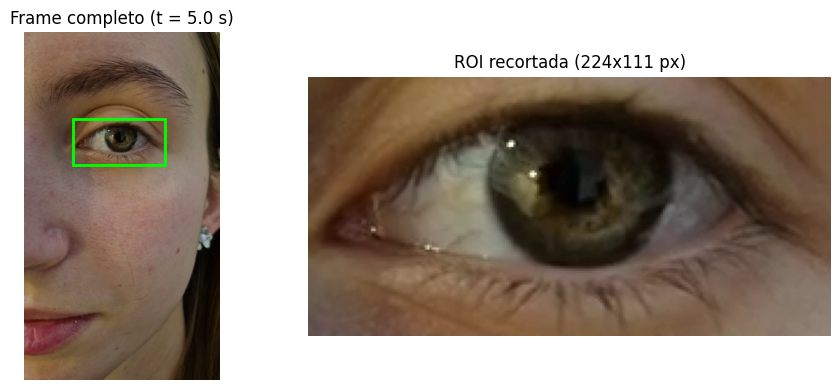

In [3]:
frame = cm.extraer_frame(VIDEO_PATH, TIEMPO_FRAME_REPRESENTATIVO_S)
roi_rgb = cm.recortar_roi(frame, ROI)
x0, x1, y0, y1 = cm.roi_a_pixeles(frame.shape, ROI)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(frame)
ax[0].add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                   edgecolor="lime", facecolor="none", linewidth=2))
ax[0].set_title(f"Frame completo (t = {TIEMPO_FRAME_REPRESENTATIVO_S} s)")
ax[0].axis("off")

ax[1].imshow(roi_rgb)
ax[1].set_title(f"ROI recortada ({roi_rgb.shape[1]}x{roi_rgb.shape[0]} px)")
ax[1].axis("off")
plt.tight_layout()
plt.show()

## 3. Paso 2 — Escala de grises + CLAHE

Primero se pasa la ROI a un solo canal con `cf.conv_grises` (conversión estándar de
OpenCV, equivalente a $Y = 0.299R + 0.587G + 0.114B$). Después se le aplica **CLAHE**
(*Contrast Limited Adaptive Histogram Equalization*, `cf.aplicar_clahe`): ecualiza el
histograma **por bloques** (grilla de `clahe_grilla`×`clahe_grilla`) con el pico de cada
histograma limitado a `clahe_clip`, para realzar la pupila y el iris sin amplificar el
ruido de las zonas uniformes. Es el mismo preprocesamiento que usa `seg.segmentar_pupila`
antes de Watershed (paso siguiente).

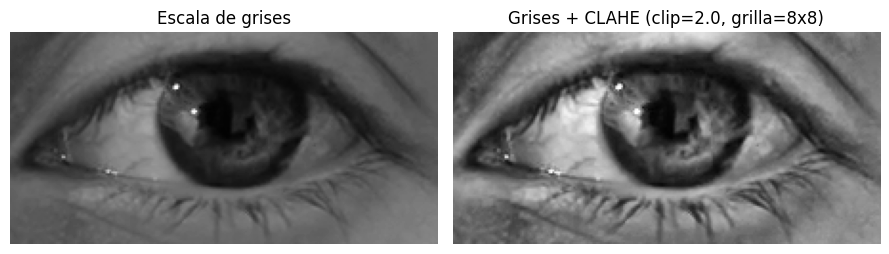

In [4]:
p12 = cfg["modulo1_2"]
gris = cf.conv_grises(roi_rgb)
gris_clahe = cf.aplicar_clahe(gris, p12["clahe_clip"], p12["clahe_grilla"])

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(gris, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Escala de grises")
ax[0].axis("off")
ax[1].imshow(gris_clahe, cmap="gray", vmin=0, vmax=255)
ax[1].set_title(f"Grises + CLAHE (clip={p12['clahe_clip']}, grilla={p12['clahe_grilla']}x{p12['clahe_grilla']})")
ax[1].axis("off")
plt.tight_layout()
plt.show()

## 4. Paso 3 — Segmentación con Watershed

`seg.segmentar_pupila` (que internamente llama a los pasos de abajo) hace:

1. **Estimar el centro y radio de la pupila** (`seg.estimar_pupila`): barre distintos
   radios $r$ y, para cada uno, mide el contraste de un disco oscuro rodeado de un anillo
   más claro. Primero busca el **iris** (disco grande) y después, solo cerca de su centro,
   la **pupila** (disco chico dentro del iris).
2. **Marcadores** (`seg.crear_marcadores`): a partir de $(c_x, c_y, r)$ se arman tres zonas
   según la distancia $d$ de cada píxel al centro:
   - $d \le 0.5\,r$ → marcador 1 (semilla de la pupila, certeza).
   - $1.3\,r \le d \le 1.8\,r$ → marcador 2 (semilla del fondo, certeza).
   - el resto → 0 (incertidumbre; ahí decide Watershed).
3. **Gradiente de Sobel** (`seg.calcular_gradiente_sobel`): magnitud
   $\sqrt{(\partial I/\partial x)^2 + (\partial I/\partial y)^2}$, que actúa como "relieve":
   alto en los bordes (pupila-iris), bajo en zonas uniformes.
4. **Watershed** (`skimage.segmentation.watershed`, en `seg.segmentar_watershed`): "inunda"
   el relieve desde los marcadores; cada cuenca termina en la etiqueta de su marcador. La
   máscara de la pupila es la región que terminó con la etiqueta 1.

Pupila estimada: centro=(112.0, 46.0) px, radio=13.0 px
Iris estimado:   centro=(117.0, 45.0) px, radio=36.0 px


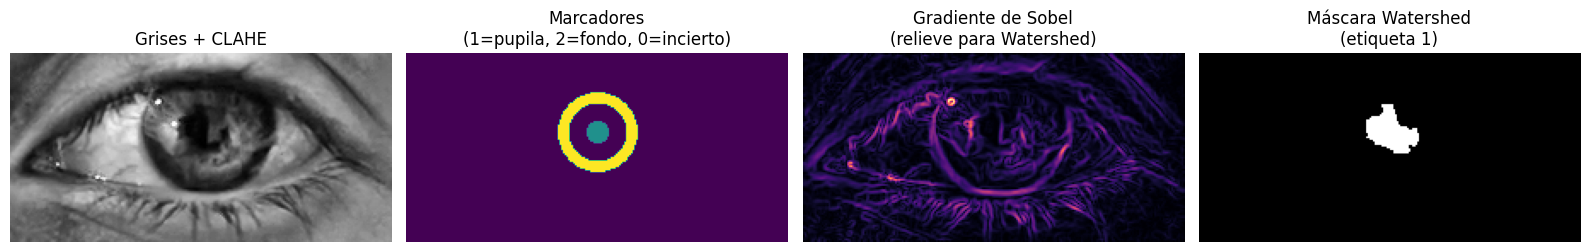

In [5]:
pupila_est, iris_est = seg.estimar_pupila(gris_clahe, devolver_iris=True)
cx, cy, r = pupila_est
w = cfg["modulo2"]["watershed"]
marcadores = seg.crear_marcadores(gris_clahe, cx, cy, r,
                                  w["factor_interior"], w["factor_anillo_interior"],
                                  w["factor_anillo_exterior"])
gradiente = seg.calcular_gradiente_sobel(gris_clahe)
mascara_ws_bool, etiquetas = seg.segmentar_watershed(gris_clahe, marcadores)
mascara_ws = mascara_ws_bool.astype(np.uint8) * 255

print(f"Pupila estimada: centro=({cx:.1f}, {cy:.1f}) px, radio={r:.1f} px")
print(f"Iris estimado:   centro=({iris_est[0]:.1f}, {iris_est[1]:.1f}) px, radio={iris_est[2]:.1f} px")

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(gris_clahe, cmap="gray")
ax[0].set_title("Grises + CLAHE")
ax[1].imshow(marcadores, cmap="viridis")
ax[1].set_title("Marcadores\n(1=pupila, 2=fondo, 0=incierto)")
ax[2].imshow(gradiente, cmap="magma")
ax[2].set_title("Gradiente de Sobel\n(relieve para Watershed)")
ax[3].imshow(mascara_ws, cmap="gray")
ax[3].set_title("Máscara Watershed\n(etiqueta 1)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

## 5. Paso 4 — Erosión morfológica y componente principal

Watershed suele sobre-segmentar un poco el borde pupilar. El Módulo 2.2 barrió varias
operaciones morfológicas contra la anotación manual y la que mejor Dice dio fue
**erosión** con kernel elíptico `k=3` y `2` iteraciones (ver `config.yaml →
modulo3.morfologia`). La erosión (`cv2.erode`) recorre la máscara con un elemento
estructurante $k\times k$ y deja en 255 solo los píxeles cuya vecindad **completa** es
255: reduce el borde de la región blanca hacia adentro, achicando la pupila y
desprendiendo salientes delgadas.

Después de erosionar puede quedar algún grupito de píxeles suelto; con
`cv2.connectedComponentsWithStats` (`de.componente_principal`) nos quedamos con la región
conexa más grande, porque la pupila es una sola. Todo esto está encapsulado en
`de.mascara_pupila`, que es la función que usa el resto del Módulo 3 (incluido el video,
paso 6).

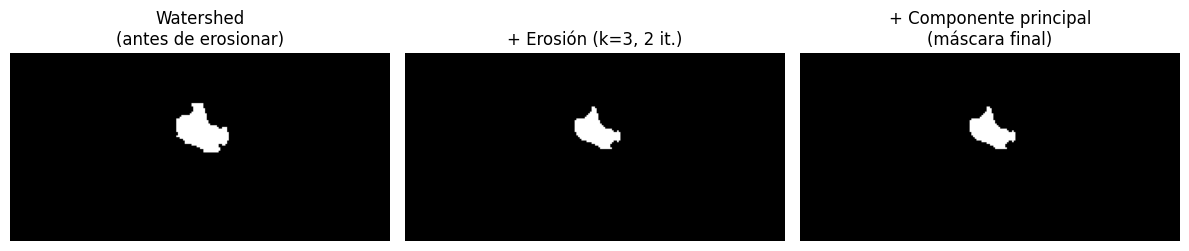

Área antes de erosionar:  530 px
Área máscara final:       349 px


In [6]:
m3 = cfg["modulo3"]["morfologia"]
mascara_erosionada = morf.erosion(mascara_ws, m3["kernel"], m3["iteraciones"], m3["kernel_forma"])
mascara_final = de.componente_principal(mascara_erosionada)

# Lo mismo, pero con la función de pipeline que usa el resto del notebook/Módulo 3:
resultado_frame = de.mascara_pupila(roi_rgb, cfg)
assert np.array_equal(resultado_frame["mascara"], mascara_final)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(mascara_ws, cmap="gray")
ax[0].set_title("Watershed\n(antes de erosionar)")
ax[1].imshow(mascara_erosionada, cmap="gray")
ax[1].set_title(f"+ Erosión (k={m3['kernel']}, {m3['iteraciones']} it.)")
ax[2].imshow(mascara_final, cmap="gray")
ax[2].set_title("+ Componente principal\n(máscara final)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

print(f"Área antes de erosionar:  {(mascara_ws > 0).sum()} px")
print(f"Área máscara final:       {(mascara_final > 0).sum()} px")

## 6. Paso 5 — Características (Módulo 3.1)

Con la máscara final se calculan los tres grupos de descriptores del punto 3.1:

**a) Morfometría** (`de.morfometria`), a partir de la máscara binaria:
- Área $A$ = cantidad de píxeles.
- Perímetro $P$ = longitud del contorno externo (`cv2.arcLength`).
- Centroide $(X_c, Y_c) = (m_{10}/m_{00},\; m_{01}/m_{00})$ (momentos de orden 1 sobre el de orden 0).
- **Diámetro equivalente** (el del círculo de igual área): $D = 2\sqrt{A/\pi}$ — esta es
  la $D$ que se usa en las curvas $D(t)$ del paso 6/7.
- Circularidad $C = 4\pi A_c / P^2$ (1 = círculo perfecto, baja con formas irregulares).
- Excentricidad, a partir de los momentos centrales de orden 2
  $\mu_{20}, \mu_{02}, \mu_{11}$ (la "matriz de covarianza" de la región):
  $$\lambda_{1,2} = \frac{\mu_{20}+\mu_{02}}{2} \pm \sqrt{\left(\frac{\mu_{20}-\mu_{02}}{2}\right)^2 + \mu_{11}^2}, \qquad e = \sqrt{1 - \lambda_2/\lambda_1}$$
  ($e=0$ círculo, $e\to1$ elipse muy alargada).

**b) Textura de primer orden** (`de.primer_orden`), sobre el histograma de cada canal
(R, G, B) dentro de la pupila y del iris: media $\mu$, desvío $\sigma$, asimetría
$E[(x-\mu)^3]/\sigma^3$ y entropía $H=-\sum p_k \log_2 p_k$ (en bits, sobre la imagen
cuantizada a `niveles_gris`).

**c) Textura de segundo orden — GLCM** (`de.tabla_glcm`): la matriz de co-ocurrencia
$P(i,j)$ cuenta pares de píxeles vecinos (distancia $d$, ángulo $\theta$) con niveles de
gris $i$ y $j$; se promedia sobre varias distancias/ángulos (textura sin dirección
preferida) y se resume en 4 atributos de Haralick:
$$\text{contraste}=\sum (i-j)^2 P(i,j), \quad \text{homogeneidad}=\sum \frac{P(i,j)}{1+(i-j)^2}, \quad \text{energía}=\sum P(i,j)^2, \quad \text{correlación}=\sum \frac{(i-\mu_i)(j-\mu_j)P(i,j)}{\sigma_i \sigma_j}$$

In [7]:
# a) Morfometría
morfo = de.morfometria(resultado_frame["mascara"])
df_morfo = pd.DataFrame([morfo])
display(df_morfo)

,area_px,perimetro_px,cx,cy,diametro_eq_px,circularidad,excentricidad,eje_mayor_px,eje_menor_px,orientacion_grados
0,349,87.254833,111.845272,45.977077,21.079862,0.513324,0.787172,28.617067,17.649122,32.018272


In [8]:
# b) Textura de primer orden: regiones pupila e iris
gris_frame = resultado_frame["gris"]
mascara_frame = resultado_frame["mascara"]
_, iris_frame = seg.estimar_pupila(gris_frame, devolver_iris=True)

ri = cfg["modulo3"]["region_iris"]
region_iris_bool = de.region_iris(gris_frame, mascara_frame, iris_frame,
                                  ri["factor_iris"], ri["margen_pupila_px"],
                                  ri["fila_min_rel"], ri["k_reflejo"])
regiones = {"pupila": mascara_frame > 0, "iris": region_iris_bool}

niveles_principal = cfg["modulo3"]["niveles_gris"][0]
df_primer_orden = de.tabla_primer_orden(roi_rgb, regiones, niveles_principal)
display(df_primer_orden)

,region,canal,media,desvio,entropia_bits,asimetria,n_pixeles
0,pupila,R,12.653295,9.918442,2.025690,0.876256,349
1,pupila,G,11.226361,10.668369,1.849836,1.417566,349
2,pupila,B,8.372493,10.497861,1.411919,1.725640,349
3,iris,R,48.777724,19.470938,3.233817,0.721064,2056
4,iris,G,41.824416,18.435127,3.108941,0.900696,2056
5,iris,B,26.643969,14.015128,2.744527,0.825801,2056


In [9]:
# c) Textura de segundo orden: GLCM
g = cfg["modulo3"]["glcm"]
df_glcm, _matrices_glcm = de.tabla_glcm(roi_rgb, regiones, cfg["modulo3"]["niveles_gris"],
                                        g["distancias"], g["angulos_grados"])
display(df_glcm)

,niveles,region,canal,contraste,homogeneidad,energia,correlacion
0,32,pupila,R,0.681481,0.768689,0.168911,0.788303
1,32,pupila,G,0.550083,0.820508,0.276854,0.848010
2,32,pupila,B,0.543701,0.852227,0.429102,0.847559
3,32,iris,R,1.039220,0.692457,0.042084,0.910499
4,32,iris,G,1.016541,0.702889,0.051328,0.901693
5,32,iris,B,0.933730,0.714738,0.069458,0.847755
6,64,pupila,R,2.235303,0.635579,0.065956,0.819127
7,64,pupila,G,2.087244,0.684914,0.106483,0.857593
8,64,pupila,B,2.018277,0.720306,0.146170,0.857124
9,64,iris,R,3.665478,0.512939,0.012648,0.919875


## 7. Paso 6 — Procesar el video completo: curvas $A(t)$ y $D(t)$

`din.procesar_registro` repite los pasos 1 a 4 en **cada frame** del video y arma la
curva temporal completa:

1. **`din.recorrer_video`**: por cada frame, mide el brillo medio (para detectar el
   estímulo luminoso) y llama a `de.mascara_pupila` → `de.morfometria`, guardando área,
   diámetro, centroide, circularidad y excentricidad.
2. **`din.limpiar_senal`**: marca como no confiables los frames sin pupila detectada
   (parpadeo), con forma muy irregular/alargada, con un salto brusco del centroide, o que
   el filtro de **Hampel** señala como atípicos en el diámetro
   ($|D-\text{mediana}| > k\cdot 1.4826\cdot\text{MAD}$ en una ventana móvil). Los huecos
   cortos se interpolan linealmente.
3. **`din.agregar_suavizado`**: mediana móvil (saca picos aislados) + filtro gaussiano
   (pasa-bajos) sobre $D(t)$ y $A(t)$, y calcula la velocidad $v(t) = dD/dt$ por diferencias
   finitas (`np.gradient`).
4. **`din.detectar_estimulos`** y **`din.extraer_parametros`**: detectan el encendido/apagado
   de la luz (salto de brillo) y, si hay, los parámetros fisiológicos de cada respuesta
   (latencia, amplitud, velocidad pico).
5. Si hay escala (iris ≈ 11,7 mm), agrega las columnas en milímetros.

**Esto puede tardar varios minutos** si el video tiene muchos frames (se segmenta la
pupila en cada uno). Para una vista rápida, se puede subir `paso_frames` (procesa 1 de
cada N frames) editando `cfg["modulo3"]["video"]["paso_frames"]` antes de correr la celda.

In [10]:
resultado = din.procesar_registro(VIDEO_PATH, cfg, roi=ROI, verbose=True)
curva = resultado["curva"]
estimulos = resultado["estimulos"]
parametros = resultado["parametros"]
if resultado["mm_por_px"]:
    print(f"Escala: {resultado['mm_por_px']:.5f} mm/px (a partir del radio del iris)")
display(curva.head())

  frame 0
  frame 100
  frame 200
  frame 300
  frame 400
  frame 500
  frame 600
  frame 700
  frame 800
  frame 900
  frame 1000
Escala: 0.16250 mm/px (a partir del radio del iris)


,frame,t_s,brillo,detectada,radio_estimado_px,area_px,perimetro_px,cx,cy,circularidad,...,diametro_limpio_px,area_limpia_px,interpolado,diametro_suave_px,area_suave_px,velocidad_px_s,diametro_mm,diametro_limpio_mm,diametro_suave_mm,velocidad_mm_s
0,0,0.000000,96.059520,True,15.0,569,104.325901,111.843585,49.265378,0.604425,...,26.916042,569.0,False,26.084716,534.700829,-3.118035,4.373857,4.373857,4.238766,-0.506681
1,1,0.033402,96.151002,True,15.0,545,99.840620,112.772477,48.884404,0.630956,...,26.342277,545.0,False,25.980568,530.454827,-3.065138,4.280620,4.280620,4.221842,-0.498085
2,2,0.066804,96.154024,True,15.0,559,102.911687,112.903399,50.016100,0.609879,...,26.678473,559.0,False,25.879954,526.351140,-2.764662,4.335252,4.335252,4.205493,-0.449258
3,3,0.100205,96.103318,True,13.0,497,85.012193,113.436620,49.275654,0.798975,...,25.155517,497.0,False,25.795879,522.916960,-2.061726,4.087772,4.087772,4.191830,-0.335030
4,4,0.133607,96.206567,True,13.0,500,84.183766,113.550000,49.962000,0.820096,...,25.231325,500.0,False,25.742224,520.714745,-0.997895,4.100090,4.100090,4.183111,-0.162158


## 8. Paso 7 — Graficar $A(t)$ y $D(t)$

Se grafican el diámetro y el área crudos (puntos, solo frames válidos) contra la curva
suavizada, y la velocidad $v(t)=dD/dt$. Las líneas verticales marcan los estímulos
detectados (verde = encendido de la luz, rojo = apagado).

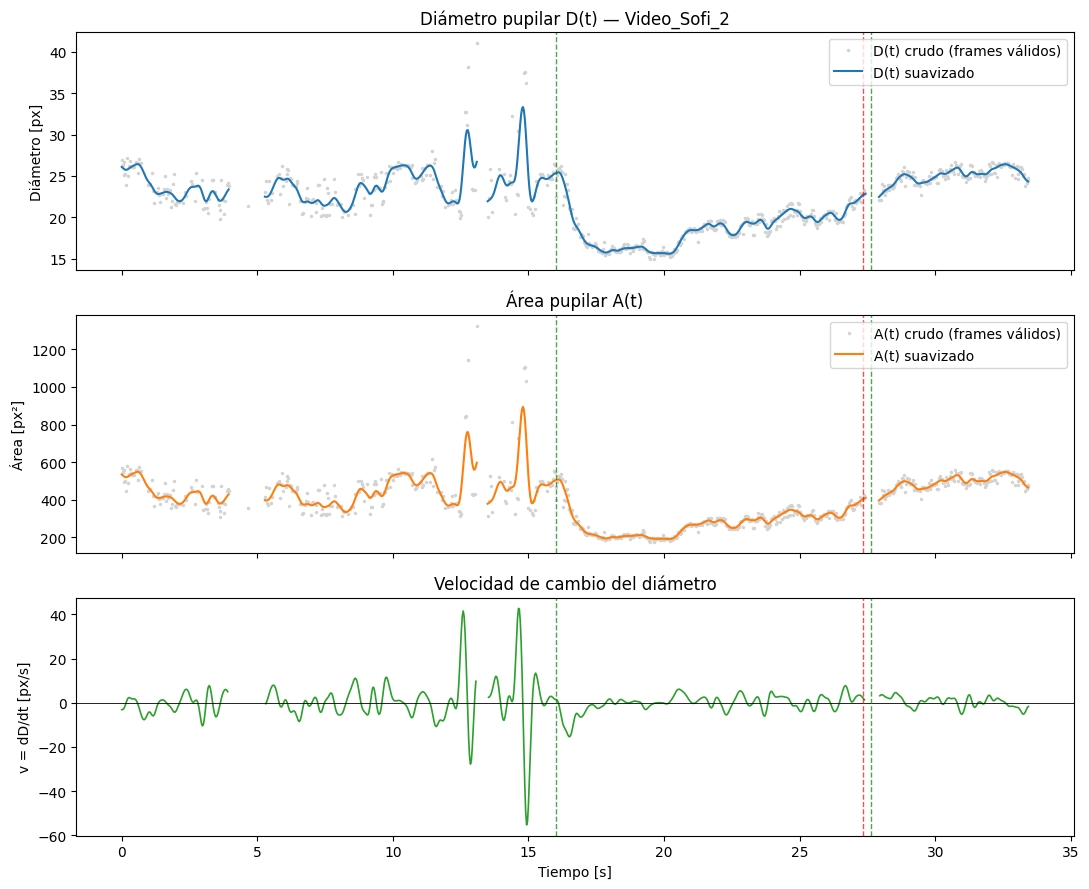

,tipo,t_estimulo_s,t_inicio_s,latencia_s,t_extremo_s,D_basal_px,D_inicio_px,D_extremo_px,amplitud_D_px,amplitud_D_pct,...,respuesta_detectada,extremo_en_borde,inicio_en_borde,en_interpolado,D_basal_mm,D_extremo_mm,amplitud_D_mm,amplitud_desde_inicio_D_mm,v_pico_mm_s,v_media_mm_s
0,constriccion,16.032857,16.166464,0.133607,17.869955,24.646241,25.328956,15.731196,8.915044,36.172025,...,True,False,False,False,4.005014,2.556319,1.448695,1.559636,2.497644,0.915553
1,redilatacion,27.322660,NaN,NaN,27.422866,21.539547,22.661422,22.820540,1.280993,5.947168,...,False,False,True,False,3.500176,3.708338,0.208161,0.025857,NaN,NaN
2,constriccion,27.623276,NaN,NaN,29.393571,21.792812,25.167122,24.074629,2.281817,10.470503,...,False,False,False,False,3.541332,3.912127,0.370795,0.177530,NaN,NaN


In [11]:
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

ax[0].plot(curva.t_s[curva.valido], curva.diametro_px[curva.valido], ".", color="lightgray",
          markersize=3, label="D(t) crudo (frames válidos)")
ax[0].plot(curva.t_s, curva.diametro_suave_px, color="C0", linewidth=1.5, label="D(t) suavizado")
ax[0].set_ylabel("Diámetro [px]")
ax[0].set_title(f"Diámetro pupilar D(t) — {REGISTRO}")
ax[0].legend(loc="upper right")

ax[1].plot(curva.t_s[curva.valido], curva.area_px[curva.valido], ".", color="lightgray",
          markersize=3, label="A(t) crudo (frames válidos)")
ax[1].plot(curva.t_s, curva.area_suave_px, color="C1", linewidth=1.5, label="A(t) suavizado")
ax[1].set_ylabel("Área [px²]")
ax[1].set_title("Área pupilar A(t)")
ax[1].legend(loc="upper right")

ax[2].plot(curva.t_s, curva.velocidad_px_s, color="C2", linewidth=1.2)
ax[2].axhline(0, color="black", linewidth=0.6)
ax[2].set_ylabel("v = dD/dt [px/s]")
ax[2].set_xlabel("Tiempo [s]")
ax[2].set_title("Velocidad de cambio del diámetro")

for a in ax:
    for te in estimulos["encendido"]:
        a.axvline(te, color="green", linestyle="--", linewidth=1, alpha=0.7)
    for te in estimulos["apagado"]:
        a.axvline(te, color="red", linestyle="--", linewidth=1, alpha=0.7)

plt.tight_layout()
plt.show()

if len(parametros):
    display(parametros)
else:
    print("No se detectaron respuestas fisiológicas (ningún estímulo de luz en este video).")

## 9. Paso 8 — Exportar resultados

`din.exportar_csv` guarda `<registro>_curva.csv` (columnas estandarizadas de la curva
frame a frame) y `<registro>_parametros.csv` (parámetros fisiológicos de cada respuesta,
si hubo estímulos) en `results/modulo3/`, igual formato que los videos ya procesados en
el repo (`Video_Sofi_1`, `Video_Sofi_2`, `Video_Delca_1`).

In [12]:
ruta_curva, ruta_parametros = din.exportar_csv(resultado, REGISTRO, carpeta_res)
print(f"Curva guardada en:      {ruta_curva}")
print(f"Parámetros guardados en: {ruta_parametros}")

Curva guardada en:      c:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB\results\modulo3\Video_Sofi_2_curva.csv
Parámetros guardados en: c:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB\results\modulo3\Video_Sofi_2_parametros.csv
